In [39]:
import numpy as np
import ifcopenshell
import heapq
import matplotlib.pyplot as plt

# for some reason ifcopenshell.api is not imported when importing ifcopenshell, so we need to import it explicitly
import ifcopenshell.api.root
import ifcopenshell.api.unit
import ifcopenshell.api.context
import ifcopenshell.api.project
import ifcopenshell.api.geometry

model = ifcopenshell.open("Function_Model_v3.ifc")

# defined as a dictionary, because there can be multiple boundaries related by openings
def get_boundary_room(space):
    b_room = {}
    for boundary in space.BoundedBy:
        corr_boundary = boundary.CorrespondingBoundary
        b_room[boundary.RelatedBuildingElement.Name] = corr_boundary.RelatingSpace
    return b_room

def get_openings(space):
    openings = {}
    for boundary in space.BoundedBy:
        if boundary.RelatedBuildingElement.is_a("IfcOpeningElement"):
            openings[boundary.RelatedBuildingElement.Name] = boundary.RelatedBuildingElement
    return openings

def get_coordinates(entity):
    matrix = ifcopenshell.util.placement.get_local_placement(entity.ObjectPlacement)
    return matrix[:,3][0:3]

###### other functions to add later:
# get length/width of a space
# calculate distance between spaces




Do the edge weightings need to be known before implementing the algorithm?
Probably not, but
since I'm finding the worst case from a given building, there is no "start". So I guess will need to iterate through every path anyway?


In [40]:
import networkx as nx
import plotly.graph_objects as go

def build_nx_space_graph(model):
    """Build a graph of IfcSpaces connected through IfcOpeningElements."""
    G = nx.Graph()

    for space in model.by_type("IfcSpace"):
        s1 = space.Name or f"IfcSpace_{space.id()}"
        G.add_node(s1, ifc_id=space.id())

        for b in getattr(space, "BoundedBy", []):
            if not b.is_a("IfcRelSpaceBoundary2ndLevel"):
                continue

            cb = getattr(b, "CorrespondingBoundary", None)
            if not cb:
                continue

            elem = getattr(b, "RelatedBuildingElement", None)
            if not elem or not elem.is_a("IfcOpeningElement"):
                continue

            s2_obj = cb.RelatingSpace
            s2 = s2_obj.Name or f"IfcSpace_{s2_obj.id()}"
            opening_name = elem.Name or f"IfcOpeningElement_{elem.id()}"

            if not G.has_edge(s1, s2):
                G.add_edge(
                    s1,
                    s2,
                    opening=opening_name,
                    opening_id=elem.id(),
                    boundary_id=b.id(),
                    corresponding_boundary_id=cb.id(),
                )

    return G

G = build_nx_space_graph(model)

In [41]:
# Keep the relationship spaces and boundary spaces separate.
graph_space_by_node = {
    space.Name or f"IfcSpace_{space.id()}": space
    for space in model.by_type("IfcSpace")
    if not getattr(space, "BoundedBy", [])
}

boundary_space_by_node = {
    space.Name or f"IfcSpace_{space.id()}": space
    for space in model.by_type("IfcSpace")
    if getattr(space, "BoundedBy", [])
}

In [42]:
import heapq
import networkx as nx
import ifcopenshell.geom
from shapely.geometry import MultiPoint

# Map graph nodes to the duplicate spaces containing boundary relationships.
space_by_node = boundary_space_by_node


def node_coordinates(node):
    """Return the x, y coordinates for a graph node."""
    return get_coordinates(space_by_node[node])[:2]


geometry_settings = ifcopenshell.geom.settings()


def get_space_wall_footprints(node):
    """Return 2D wall footprints forming the space boundary."""
    space = space_by_node[node]
    walls = []

    for boundary in getattr(space, "BoundedBy", []):
        wall = getattr(boundary, "RelatedBuildingElement", None)
        if wall is not None and wall.is_a("IfcWall"):
            walls.append(wall)

    if not walls:
        wall_prefix = f"{node}wall".lower()
        walls = [
            wall
            for wall in model.by_type("IfcWall")
            if (wall.Name or "").lower().startswith(wall_prefix)
        ]

    wall_footprints = []
    for wall in walls:
        try:
            shape = ifcopenshell.geom.create_shape(geometry_settings, wall)
        except RuntimeError:
            continue

        vertices = np.asarray(shape.geometry.verts).reshape(-1, 3)
        transform = np.asarray(shape.transformation.matrix).reshape(4, 4)
        homogeneous_vertices = np.column_stack(
            (vertices, np.ones(len(vertices)))
        )
        world_vertices = (homogeneous_vertices @ transform)[:, :3]
        footprint = MultiPoint(world_vertices[:, :2]).convex_hull
        if not footprint.is_empty:
            wall_footprints.append(footprint)

    return wall_footprints


def furthest_coordinates_from_opening(node, opening):
    """Return the wall point farthest from the edge opening."""
    opening_coordinates = get_coordinates(opening)[:2]
    wall_footprints = get_space_wall_footprints(node)

    if wall_footprints:
        candidate_points = np.vstack([
            np.asarray(footprint.exterior.coords)
            for footprint in wall_footprints
        ])
        distances = np.linalg.norm(
            candidate_points - opening_coordinates,
            axis=1,
        )
        return candidate_points[np.argmax(distances)]

    space_coordinates = node_coordinates(node)
    direction_away_from_opening = space_coordinates - opening_coordinates
    return space_coordinates + direction_away_from_opening


def edge_cost(graph, current, neighbor, start=None, entry_opening=None):
    """Measure from the current position to the next opening."""
    opening_id = graph.edges[current, neighbor].get("opening_id")
    if opening_id is None:
        return float(np.linalg.norm(
            node_coordinates(current) - node_coordinates(neighbor)
        ))

    opening = model.by_id(opening_id)
    if current == start:
        current_coordinates = furthest_coordinates_from_opening(
            current,
            opening,
        )
    elif entry_opening is not None:
        current_coordinates = get_coordinates(entry_opening)[:2]
    else:
        current_coordinates = node_coordinates(current)

    return float(np.linalg.norm(
        current_coordinates - get_coordinates(opening)[:2]
    ))


def final_exit_cost(graph, previous, goal, exit_opening_name=None):
    """Return the distance across the goal space to its exit opening."""
    entering_opening_id = graph.edges[previous, goal].get("opening_id")

    if exit_opening_name is not None:
        exit_openings = [
            opening
            for opening in model.by_type("IfcOpeningElement")
            if opening.Name == exit_opening_name
        ]
    else:
        goal_space = space_by_node[goal]
        goal_openings = [
            boundary.RelatedBuildingElement
            for boundary in getattr(goal_space, "BoundedBy", [])
            if (
                boundary.is_a("IfcRelSpaceBoundary2ndLevel")
                and getattr(boundary, "RelatedBuildingElement", None)
                and boundary.RelatedBuildingElement.is_a("IfcOpeningElement")
            )
        ]
        exit_openings = [
            opening
            for opening in goal_openings
            if opening.id() != entering_opening_id
        ]

    if len(exit_openings) != 1:
        raise ValueError(
            f"Expected one exit opening for {goal!r}; "
            "pass exit_opening_name to a_star when it is not a second "
            "opening in the goal space"
        )

    entering_coordinates = get_coordinates(
        model.by_id(entering_opening_id)
    )[:2]
    exit_coordinates = get_coordinates(exit_openings[0])[:2]
    return float(np.linalg.norm(entering_coordinates - exit_coordinates))


def h_n(current, goal):
    """Euclidean heuristic."""
    return float(np.linalg.norm(
        node_coordinates(current) - node_coordinates(goal)
    ))


def a_star(graph, start, goal, exit_opening_name=None):
    """Find the shortest path and include the goal-room exit distance."""
    if start not in graph:
        raise ValueError(f"Unknown start node: {start}")

    if goal not in graph:
        raise ValueError(f"Unknown goal node: {goal}")

    open_set = [(h_n(start, goal), 0.0, start)]
    g_score = {start: 0.0}
    came_from = {}

    while open_set:
        _, current_cost, current = heapq.heappop(open_set)

        if current_cost > g_score.get(current, float("inf")):
            continue

        if current == goal:
            path = [current]
            while current in came_from:
                current = came_from[current]
                path.append(current)

            path.reverse()
            distance = g_score[goal]
            if len(path) > 1:
                distance += final_exit_cost(
                    graph,
                    path[-2],
                    goal,
                    exit_opening_name=exit_opening_name,
                )
            return path, distance

        entry_opening = None
        if current != start and current in came_from:
            previous = came_from[current]
            entry_opening_id = graph.edges[previous, current].get("opening_id")
            if entry_opening_id is not None:
                entry_opening = model.by_id(entry_opening_id)

        for neighbor in graph.neighbors(current):
            cost = edge_cost(
                graph,
                current,
                neighbor,
                start=start,
                entry_opening=entry_opening,
            )
            tentative_g_score = g_score[current] + cost

            if tentative_g_score < g_score.get(neighbor, float("inf")):
                came_from[neighbor] = current
                g_score[neighbor] = tentative_g_score
                f_score = tentative_g_score + h_n(neighbor, goal)
                heapq.heappush(
                    open_set,
                    (f_score, tentative_g_score, neighbor)
                )

    raise nx.NetworkXNoPath(
        f"No path exists between {start!r} and {goal!r}"
    )

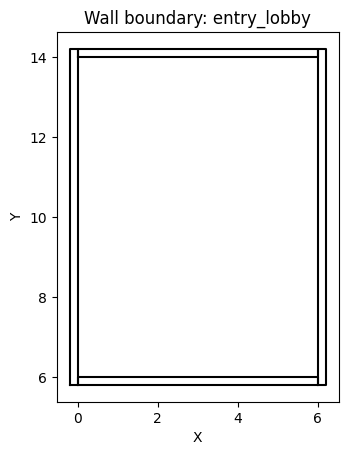

In [43]:
def draw_space_wall_boundary(node):
    """Draw the 2D footprints of walls bounding a space."""
    fig, axis = plt.subplots()

    for footprint in get_space_wall_footprints(node):
        x_values, y_values = footprint.exterior.xy
        axis.plot(x_values, y_values, "k-")

    axis.set_aspect("equal")
    axis.set_title(f"Wall boundary: {node}")
    axis.set_xlabel("X")
    axis.set_ylabel("Y")
    plt.show()


draw_space_wall_boundary("entry_lobby")

In [44]:
# start = list(G.nodes)[0]
start = "entry_lobby"
goal1 = "ne_lobby" # exit name = "north_exit"
goal2 = "entry_lobby" # exit name = "south_exit"
goal3 = "s2_office" # exit name = "west_exit"
# note: the goal is currently set to the lobby, but it should be set to the exit door of these rooms


for room in list(G.nodes):
    print("Room:", room)
    path, distance = a_star(G, room, goal1, exit_opening_name="north_exit")

    print("Path:", path)
    print("Distance:", distance)

# print("Room:", start)
# path, distance = a_star(G, start, goal1, exit_opening_name="north_exit")
# print("Path:", path)
# print("Distance:", distance)


# for room in list(G.nodes):
#     path, distance = a_star(G, room, goal2)

#     # print("Path:", path)
#     print("Distance:", distance)

# for room in list(G.nodes):
#     path, distance = a_star(G, room, goal3)

#     # print("Path:", path)
#     print("Distance:", distance)

Room: entry_lobby
Path: ['entry_lobby', 'west_corridor', 'east_corridor', 'ne_lobby']
Distance: 31.139039210657348
Room: west_corridor
Path: ['west_corridor', 'east_corridor', 'ne_lobby']
Distance: 23.914121339790142
Room: s1_office
Path: ['s1_office', 'west_corridor', 'east_corridor', 'ne_lobby']
Distance: 27.822305219958757
Room: s2_office
Path: ['s2_office', 'west_corridor', 'east_corridor', 'ne_lobby']
Distance: 24.858508366341326
Room: s3_office
Path: ['s3_office', 'east_corridor', 'ne_lobby']
Distance: 18.523328900661113
Room: east_corridor
Path: ['east_corridor', 'ne_lobby']
Distance: 13.828581265516153
Room: east_lobby
Path: ['east_lobby', 'east_corridor', 'ne_lobby']
Distance: 17.742647199775483
Room: n1_office
Path: ['n1_office', 'west_corridor', 'east_corridor', 'ne_lobby']
Distance: 29.08200376483027
Room: north_corridor
Path: ['north_corridor', 'west_corridor', 'east_corridor', 'ne_lobby']
Distance: 23.056383452856018
Room: n3_office
Path: ['n3_office', 'east_corridor', 'n

['entry_lobby', 'west_corridor', 's1_office', 's2_office', 's3_office', 'east_corridor', 'east_lobby', 'n1_office', 'north_corridor', 'n3_office', 'ne_lobby', 'n2_office', 'north_clean', 'north_store']


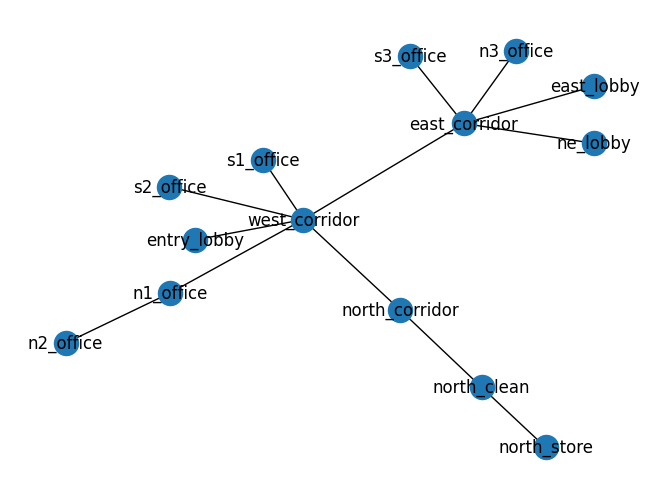

In [45]:
print(G.nodes)

goal = list(G.nodes)[-1]

# print(goal)

# use this to visualise/debug the graph
nx.draw(G, with_labels=True)
plt.show()

In [46]:
space_by_node

get_openings(model.by_id(space_by_node["ne_lobby"].id()))

{'door_ne_lobby_east_corridor': #2275=IfcOpeningElement('0adVhR9h9939bpGI7xqcyU',$,'door_ne_lobby_east_corridor',$,$,#2303,#2286,$,$)}

In [47]:
route_start = path[0]
print("Selected path:", path)
for index in range(len(path) - 1):
    current = path[index]
    neighbor = path[index + 1]
    entry_opening = None
    if index > 0:
        previous = path[index - 1]
        entry_opening_id = G.edges[previous, current]["opening_id"]
        entry_opening = model.by_id(entry_opening_id)
    print(
        current,
        "->",
        neighbor,
        edge_cost(
            G,
            current,
            neighbor,
            start=route_start,
            entry_opening=entry_opening,
        ),
    )

Selected path: ['north_store', 'north_clean', 'north_corridor', 'west_corridor', 'east_corridor', 'ne_lobby']
north_store -> north_clean 6.514598989960931
north_clean -> north_corridor 2.0
north_corridor -> west_corridor 6.199999999999999
west_corridor -> east_corridor 3.124099870362661
east_corridor -> ne_lobby 6.705221845696086


Putting it all together for the current model...

In [48]:
# For each room, calculate A* to each goal, then store the shortest cost (i.e. either goal1, goal2, or goal3)
# then identify the 3 longest travel distance cases



# start = list(G.nodes)[0]
start = "entry_lobby"
goal1 = "ne_lobby" # exit name = "north_exit"
goal2 = "entry_lobby" # exit name = "south_exit"
goal3 = "s2_office" # exit name = "west_exit"
# note: the goal is currently set to the lobby, but it should be set to the exit door of these rooms

goal = [goal1, goal2, goal3]
exit_names = {
    goal1: "north_exit",
    goal2: "south_exit",
    goal3: "west_exit"
}

# the point of this is to store an array of the 3 longest travel distances, which are saved as dictionaries with the room, goal, distance and travel path
largest_travel = []

for exit_goal in goal:

    print("-----------------------------------\n GOAL= ", exit_goal, "\n-----------------------------------")

    for room in list(G.nodes):
        print("Room", room)
        path, distance = a_star(G, room, exit_goal, exit_opening_name=exit_names[exit_goal])

        print("Path:", path)
        print("Distance: %.2f" % distance, "m\n")

        if len(largest_travel) < 3:
            travel_path = {
                "room": room,
                "goal": exit_goal,
                "distance": distance
            }
            largest_travel.append(travel_path)
            largest_travel = sorted(largest_travel, key=lambda x: x["distance"], reverse=True)
        else:
            if distance > largest_travel[-1]["distance"]:
                travel_path = {
                    "room": room,
                    "goal": exit_goal,
                    "path": path,
                    "distance": distance
                }
                largest_travel[-1] = travel_path
                largest_travel = sorted(largest_travel, key=lambda x: x["distance"], reverse=True)

# note that there is a slight inaccuracy, when the starting room is the same as the goal room, the distance is calculated as 0.
# it should really be the distance from the furthest point of the room to the exit, but this case is not interesting for the egress analysis, so is not being rectified.


-----------------------------------
 GOAL=  ne_lobby 
-----------------------------------
Room entry_lobby
Path: ['entry_lobby', 'west_corridor', 'east_corridor', 'ne_lobby']
Distance: 31.14 m

Room west_corridor
Path: ['west_corridor', 'east_corridor', 'ne_lobby']
Distance: 23.91 m

Room s1_office
Path: ['s1_office', 'west_corridor', 'east_corridor', 'ne_lobby']
Distance: 27.82 m

Room s2_office
Path: ['s2_office', 'west_corridor', 'east_corridor', 'ne_lobby']
Distance: 24.86 m

Room s3_office
Path: ['s3_office', 'east_corridor', 'ne_lobby']
Distance: 18.52 m

Room east_corridor
Path: ['east_corridor', 'ne_lobby']
Distance: 13.83 m

Room east_lobby
Path: ['east_lobby', 'east_corridor', 'ne_lobby']
Distance: 17.74 m

Room n1_office
Path: ['n1_office', 'west_corridor', 'east_corridor', 'ne_lobby']
Distance: 29.08 m

Room north_corridor
Path: ['north_corridor', 'west_corridor', 'east_corridor', 'ne_lobby']
Distance: 23.06 m

Room n3_office
Path: ['n3_office', 'east_corridor', 'ne_lobby']

In [49]:
# the details of the 3 longest travel distances from the algorithm can be printed as follows
for i in range(len(largest_travel)):
    print(largest_travel[i])


{'room': 'east_lobby', 'goal': 'entry_lobby', 'path': ['east_lobby', 'east_corridor', 'west_corridor', 'entry_lobby'], 'distance': 38.3056027165114}
{'room': 'ne_lobby', 'goal': 'entry_lobby', 'path': ['ne_lobby', 'east_corridor', 'west_corridor', 'entry_lobby'], 'distance': 37.18602593251579}
{'room': 'north_store', 'goal': 'entry_lobby', 'path': ['north_store', 'north_clean', 'north_corridor', 'west_corridor', 'entry_lobby'], 'distance': 34.13706416848141}


In [50]:
print(largest_travel[0])

{'room': 'east_lobby', 'goal': 'entry_lobby', 'path': ['east_lobby', 'east_corridor', 'west_corridor', 'entry_lobby'], 'distance': 38.3056027165114}
